# 01 - Exploratory Data Analysis
### ActivitySense AI - Human Activity Recognition | Yash Rajput - 2427010652

Understand the UCI HAR dataset: size, the six activities, the static-vs-dynamic split, and how
sensor features separate the activities.

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

In [2]:
from src.data_loader import load_train, load_test
from src.preprocessing import validate
from src import config as C, visualize as V

Xtr, ytr, ytr_name, subj_tr = load_train()
Xte, yte, yte_name, subj_te = load_test()
print("train:", Xtr.shape, "| test:", Xte.shape)
Xtr.iloc[:3, :6]

train: (7352, 561) | test: (2947, 561)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944


## Data-quality checks

In [3]:
for k, v in validate(Xtr, Xte).items():
    print(f"  {k}: {v}")
print("\ntrain subjects:", sorted(subj_tr.unique()))
print("test  subjects:", sorted(subj_te.unique()))
print("(subjects are disjoint -> official person-wise split)")

  train_rows: 7352
  test_rows: 2947
  features: 561
  columns_match: True
  missing_train: 0
  missing_test: 0
  non_finite_train: 0

train subjects: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
test  subjects: [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
(subjects are disjoint -> official person-wise split)


## Activity class distribution

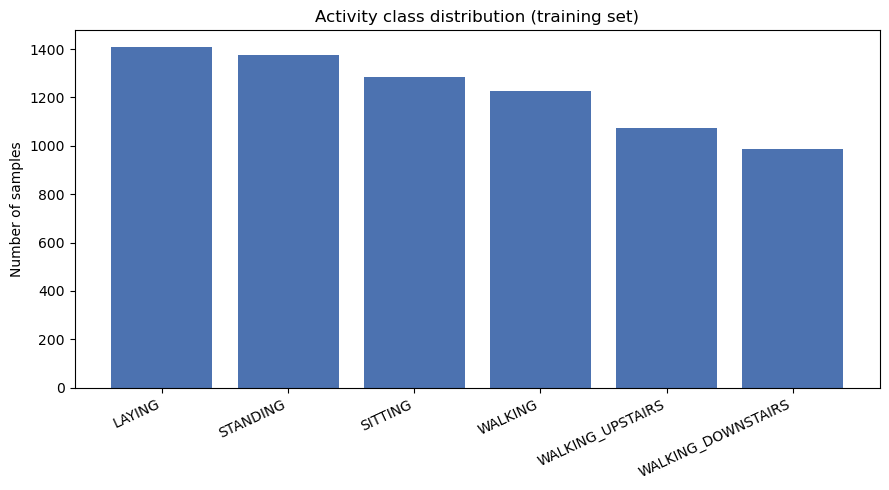

Dynamic: ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS']
Static : ['SITTING', 'STANDING', 'LAYING']


In [4]:
V.plot_activity_distribution(ytr_name.value_counts(), C.FIGURES_DIR / "activity_distribution.png")
plt.show()
print("Dynamic:", C.DYNAMIC)
print("Static :", C.STATIC)

The classes are fairly balanced. Activities split into **dynamic** (walking types) and **static** (sitting/standing/laying).

## How a single feature separates the activities\n`tBodyAccMag-mean()` (mean body-acceleration magnitude) cleanly splits dynamic from static activities.

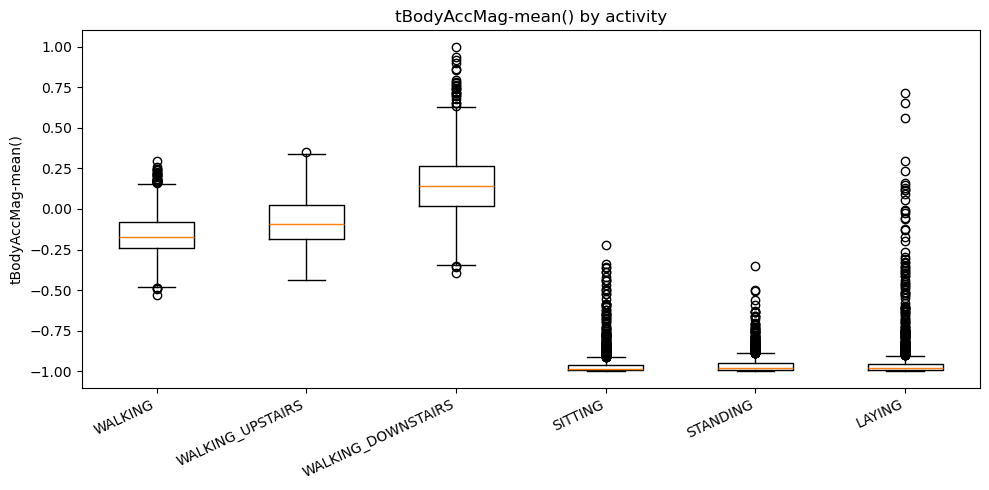

In [5]:
feat = "tBodyAccMag-mean()"
order = C.DYNAMIC + C.STATIC
data = [Xtr.loc[ytr_name == a, feat] for a in order]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(data, labels=order)
ax.set_ylabel(feat); ax.set_title(f"{feat} by activity")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.tight_layout(); plt.show()

## Two features separate activities in 2-D

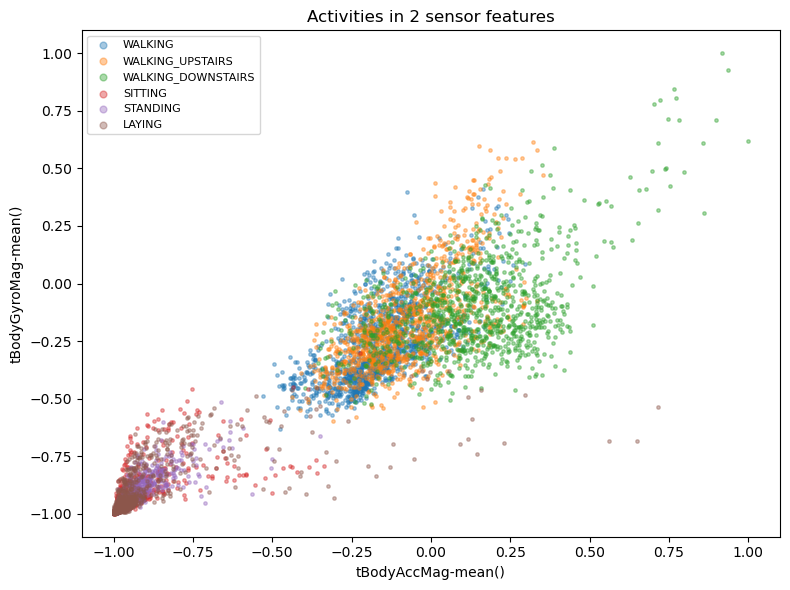

In [6]:
fx, fy = "tBodyAccMag-mean()", "tBodyGyroMag-mean()"
fig, ax = plt.subplots(figsize=(8, 6))
for a in order:
    m = ytr_name == a
    ax.scatter(Xtr.loc[m, fx], Xtr.loc[m, fy], s=6, alpha=0.4, label=a)
ax.set_xlabel(fx); ax.set_ylabel(fy); ax.set_title("Activities in 2 sensor features")
ax.legend(markerscale=2, fontsize=8); plt.tight_layout(); plt.show()

**Findings:** the dataset is clean (no missing values, train/test subjects disjoint). Acceleration
magnitude separates moving from still activities well, while the static activities (sitting,
standing, laying) overlap more - we expect those to be the harder cases for the classifier.